# 03 Statistical checks and budget scenarios

> **Simulated case study.** Glowina Skincare is a fictional brand and all data is synthetic.

Notebook 02 produced a list of findings. This notebook asks how far each one can be trusted and then sizes the main recommendation.

1. **Are the channel differences real?** With 7 to 12 campaigns per channel, a ratio can look decisive and still be noise. I put confidence intervals on net ROAS.
2. **Is the weak group weak by design?** Splitting campaigns into tiers by their own results is circular. I define a group by what the campaign is built to do and test that instead.
3. **Is conversion rate falling inside campaigns, or is the mix changing?** The two call for different fixes.
4. **What is a budget shift worth?** A scenario with stated assumptions, shown across a range of values for the assumptions I cannot know.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

CLEAN = Path("../data/clean")
ANALYTICS = Path("../data/analytics")
FIG = Path("../docs/figures")
FIG.mkdir(parents=True, exist_ok=True)

rng = np.random.default_rng(42)
N_BOOT = 10_000

plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "font.size": 10})
COLORS = {"Google Ads": "#4285F4", "Meta Ads": "#7B61FF", "TikTok Ads": "#E4405F", "Influencer": "#F5A623"}

def save_fig(name):
    plt.tight_layout()
    plt.savefig(FIG / f"{name}.png", dpi=130, bbox_inches="tight")

sc = pd.read_csv(ANALYTICS / "campaign_scorecard.csv").rename(
    columns={"spend_idr": "spend", "net_revenue_idr": "net_revenue"})
print(f"{len(sc)} campaigns, spend IDR {sc.spend.sum():,.0f}, net ROAS {sc.net_revenue.sum() / sc.spend.sum():.2f}x")

40 campaigns, spend IDR 1,417,489,500, net ROAS 1.78x

## 1. Are the channel differences real?

The unit that varies independently is the campaign, not the day. Days inside one campaign share the same audience, creative and budget, so treating 2,452 campaign-days as independent would make every interval too narrow. I resample whole campaigns within each channel 10,000 times and recompute net ROAS (total net revenue divided by total spend) each time.

In [2]:
def boot_ratio(df, n_boot=N_BOOT):
    """Cluster bootstrap: resample campaigns, return net ROAS for each resample."""
    n = len(df)
    idx = rng.integers(0, n, size=(n_boot, n))
    return df.net_revenue.to_numpy()[idx].sum(axis=1) / df.spend.to_numpy()[idx].sum(axis=1)

rows, boots = [], {}
for channel, g in sc.groupby("channel"):
    b = boot_ratio(g)
    boots[channel] = b
    rows.append({"channel": channel, "campaigns": len(g),
                 "net_roas": g.net_revenue.sum() / g.spend.sum(),
                 "ci_low": np.percentile(b, 2.5), "ci_high": np.percentile(b, 97.5),
                 "resamples_below_1": (b < 1).mean()})
ci = pd.DataFrame(rows).sort_values("net_roas", ascending=False).reset_index(drop=True)
print(ci.round(2).to_string(index=False))

print("\nShare of resamples in which the first channel beats the second:")
for a, b_ in [("Google Ads", "Meta Ads"), ("Meta Ads", "TikTok Ads"), ("TikTok Ads", "Influencer"), ("Google Ads", "TikTok Ads")]:
    print(f"  {a} > {b_}: {(boots[a] > boots[b_]).mean():.1%}")

   channel  campaigns  net_roas  ci_low  ci_high  resamples_below_1
Google Ads          9      2.81    1.24     4.89               0.00
  Meta Ads         10      2.29    1.39     3.44               0.00
TikTok Ads         10      0.94    0.62     1.40               0.61
Influencer         11      0.81    0.55     1.59               0.77

Share of resamples in which the first channel beats the second:
  Google Ads > Meta Ads: 67.0%
  Meta Ads > TikTok Ads: 99.6%
  TikTok Ads > Influencer: 64.9%
  Google Ads > TikTok Ads: 99.2%

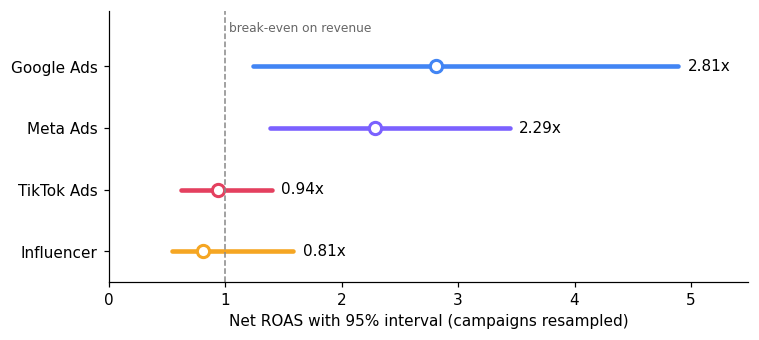

In [3]:
fig, ax = plt.subplots(figsize=(7, 3.2))
for i, r in ci.iterrows():
    ax.plot([r.ci_low, r.ci_high], [i, i], color=COLORS[r.channel], lw=3, solid_capstyle="round")
    ax.plot(r.net_roas, i, "o", color="white", mec=COLORS[r.channel], mew=2, ms=8)
    ax.text(r.ci_high + 0.08, i, f"{r.net_roas:.2f}x", va="center")
ax.axvline(1, color="#888", ls="--", lw=1)
ax.set_yticks(range(len(ci)), ci.channel)
ax.set_ylim(len(ci) - 0.5, -0.9)
ax.text(1.03, -0.62, "break-even on revenue", color="#666", fontsize=8, va="center")
ax.set_xlabel("Net ROAS with 95% interval (campaigns resampled)")
ax.set_xlim(0, ci.ci_high.max() + 0.6)
save_fig("channel_roas_intervals")

Google and Meta have intervals that sit above 1.0x. TikTok and Influencer have intervals that straddle 1.0x, so with 10 or 11 campaigns each I cannot say either channel loses money overall.

Two comparisons are clear. Meta beats TikTok in 99.6% of resamples and Google beats TikTok in 99.2%. Two are not: Google against Meta (67%) and TikTok against Influencer (65%) are too close to call.

The intervals are wide because each channel mixes very different campaign types. TikTok runs live shopping at 2.3x to 3.3x and awareness at 0.3x to 0.4x, and the channel average hides that gap. The real difference sits between campaign types, which is the next test.

## 2. Is the weak group weak by design?

Notebook 02 put 15 campaigns in a Cut tier because their net ROAS was below 1.0x. Comparing that tier with the rest proves nothing, since it was chosen by the outcome. Twelve of the 15 share a trait I can name without looking at results: they are built to create attention, not to close a sale. I define the group by objective, **awareness-type** (Awareness, Display, Macro-influencer, Celebrity), and test whether it earns less than the **performance-type** campaigns.

In [4]:
AWARENESS_TYPE = ["Awareness", "Display", "Macro-influencer", "Celebrity"]
sc["group"] = np.where(sc.objective.isin(AWARENESS_TYPE), "Awareness-type", "Performance-type")

summary = sc.groupby("group").agg(campaigns=("campaign_id", "count"), spend=("spend", "sum"),
                                  net_revenue=("net_revenue", "sum"))
summary["spend_share_pct"] = 100 * summary.spend / summary.spend.sum()
summary["net_roas"] = summary.net_revenue / summary.spend

b_aw = boot_ratio(sc[sc.group == "Awareness-type"])
b_pf = boot_ratio(sc[sc.group == "Performance-type"])
summary["ci_low"] = [np.percentile(b_aw, 2.5), np.percentile(b_pf, 2.5)]
summary["ci_high"] = [np.percentile(b_aw, 97.5), np.percentile(b_pf, 97.5)]
print(summary.round(2).to_string())

diff = b_pf - b_aw
print(f"\nPerformance-type minus awareness-type net ROAS: {summary.loc['Performance-type','net_roas'] - summary.loc['Awareness-type','net_roas']:.2f}")
print(f"95% interval for the difference: {np.percentile(diff, 2.5):.2f} to {np.percentile(diff, 97.5):.2f}")
print(f"Share of resamples where awareness-type earns more: {(b_aw > b_pf).mean():.2%}")

print("\nAwareness-type campaigns, one by one (net ROAS):")
print(sc[sc.group == "Awareness-type"].sort_values("roas_net", ascending=False)[["campaign_name", "roas_net"]].to_string(index=False))

                  campaigns      spend  net_revenue  spend_share_pct  net_roas  ci_low  ci_high
group                                                                                          
Awareness-type           12  518084400    209023000            36.55      0.40    0.34     0.46
Performance-type         28  899405100   2312010000            63.45      2.57    1.84     3.55

Performance-type minus awareness-type net ROAS: 2.17
95% interval for the difference: 1.43 to 3.15
Share of resamples where awareness-type earns more: 0.00%

Awareness-type campaigns, one by one (net ROAS):
                                       campaign_name  roas_net
    INF | Macro-influencer | Brightening Serum | Jun      0.57
INF | Macro-influencer | Daily Sunscreen SPF50 | Feb      0.55
               GGL | Display | Glow Kit Bundle | Mar      0.52
    INF | Macro-influencer | Brightening Serum | Jul      0.45
            META | Awareness | Glow Kit Bundle | Mar      0.41
           TTK | Awareness | H

Awareness-type campaigns hold 37% of spend and return 0.40x, with an interval of 0.34x to 0.46x. Performance-type campaigns hold 63% and return 2.57x. The difference is 2.17 points with an interval of 1.43 to 3.15, and no resample puts awareness-type ahead. All twelve awareness-type campaigns return less than 1.0x on their own, and the best of them reaches 0.57x, so the result does not rest on one or two bad campaigns.

This test cannot say whether awareness campaigns create demand that shows up later in brand search or retargeting. Last-click attribution gives them no credit for that. Section 4 asks how large that effect would have to be to change the recommendation.

## 3. Is conversion rate falling inside campaigns?

Notebook 02 showed monthly conversion rate falling from 2.71% in January to 1.21% in August. Two explanations fit that number. Each campaign could be getting worse (creative fatigue, audience saturation), or the budget could be moving toward campaign types that convert poorly. The first calls for refreshing campaigns. The second calls for changing where money goes.

To separate them, I compare each campaign only with itself. For every campaign-day I take its conversion rate relative to that campaign's own average, then fit a trend over time with each campaign centred on itself, weighted by clicks. The four days of the broken tracking pixel found in notebook 02 are excluded.

In [5]:
d = pd.read_csv(CLEAN / "daily_performance.csv", parse_dates=["date"])
d = d[~((d.campaign_id == "CMP-033") & d.date.between("2026-07-08", "2026-07-11"))]
d = d[d.clicks > 0].copy()
d = d.merge(sc[["campaign_id", "group"]], on="campaign_id")

d["month_idx"] = (d.date - pd.Timestamp("2026-01-01")).dt.days / 30.4
totals = d.groupby("campaign_id")[["conversions", "clicks"]].sum()
own_mean = totals.conversions / totals.clicks
d["rel_cvr"] = (d.conversions / d.clicks) / d.campaign_id.map(own_mean)

w = d.clicks
wsum = w.groupby(d.campaign_id).transform("sum")
d["x_centered"] = d.month_idx - (d.month_idx * w).groupby(d.campaign_id).transform("sum") / wsum
d["num"] = w * d.x_centered * d.rel_cvr
d["den"] = w * d.x_centered ** 2
per = d.groupby("campaign_id")[["num", "den"]].sum()
per = per[per.den > 0]

slope = per.num.sum() / per.den.sum()
idx = rng.integers(0, len(per), size=(N_BOOT, len(per)))
boot_slope = per.num.to_numpy()[idx].sum(axis=1) / per.den.to_numpy()[idx].sum(axis=1)
lo, hi = np.percentile(boot_slope, [2.5, 97.5])

print(f"Within-campaign change in conversion rate: {slope:+.1%} of a campaign's own average per month")
print(f"95% interval (campaigns resampled): {lo:+.1%} to {hi:+.1%}")
print(f"Over the 8.5 months in the data: about {slope * 8.5:+.0%}")
print(f"Campaigns used: {len(per)}")

Within-campaign change in conversion rate: -3.2% of a campaign's own average per month
95% interval (campaigns resampled): -6.5% to -0.6%
Over the 8.5 months in the data: about -27%
Campaigns used: 40

Inside a campaign, conversion rate falls by about 3% of its own average per month, roughly 27% over the period. The interval is wide (0.6% to 6.5% per month), so the size is uncertain, but it excludes zero and the direction is clear. The table below adds the mix side.

In [6]:
d["month"] = d.date.dt.strftime("%Y-%m")
m = d.groupby(["month", "group"])[["conversions", "clicks"]].sum().unstack("group")
tbl = pd.DataFrame({
    "awareness_click_share_pct": 100 * m[("clicks", "Awareness-type")] / m["clicks"].sum(axis=1),
    "cvr_awareness_pct": 100 * m[("conversions", "Awareness-type")] / m[("clicks", "Awareness-type")],
    "cvr_performance_pct": 100 * m[("conversions", "Performance-type")] / m[("clicks", "Performance-type")],
    "cvr_total_pct": 100 * m["conversions"].sum(axis=1) / m["clicks"].sum(axis=1),
})
print(tbl.round(2).to_string())

         awareness_click_share_pct  cvr_awareness_pct  cvr_performance_pct  cvr_total_pct
month                                                                                    
2026-01                        NaN                NaN                 2.71           2.71
2026-02                      41.76               0.83                 2.64           1.88
2026-03                      49.07               0.61                 2.16           1.40
2026-04                      16.70               0.46                 2.21           1.91
2026-05                      16.92               0.36                 2.09           1.80
2026-06                      42.05               0.43                 2.42           1.58
2026-07                      31.81               0.38                 1.68           1.26
2026-08                      31.54               0.70                 1.44           1.21
2026-09                      22.98               0.42                 1.70           1.41

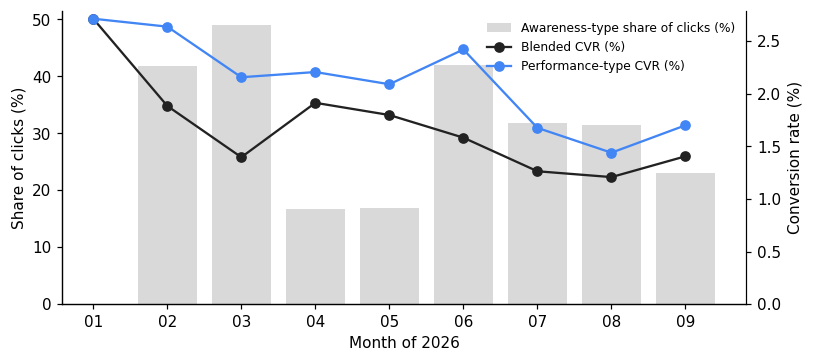

In [7]:
fig, ax1 = plt.subplots(figsize=(7.5, 3.4))
x = np.arange(len(tbl))
ax1.bar(x, tbl.awareness_click_share_pct, color="#D9D9D9", label="Awareness-type share of clicks (%)")
ax1.set_ylabel("Share of clicks (%)")
ax1.set_xticks(x, [s[5:] for s in tbl.index])
ax1.set_xlabel("Month of 2026")
ax2 = ax1.twinx()
ax2.spines["right"].set_visible(True)
ax2.plot(x, tbl.cvr_total_pct, "-o", color="#222", label="Blended CVR (%)")
ax2.plot(x, tbl.cvr_performance_pct, "-o", color="#4285F4", label="Performance-type CVR (%)")
ax2.set_ylabel("Conversion rate (%)")
ax2.set_ylim(0, None)
h1, l1 = ax1.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels()
ax1.legend(h1 + h2, l1 + l2, loc="upper right", fontsize=8, frameon=False)
save_fig("cvr_mix_shift")

Both effects are at work. Awareness-type campaigns convert at under 1% and their share of clicks swings between 17% and 49%, so the blended rate dips whenever they run heavily: March, at 49% of clicks, is the lowest month before July. Underneath those swings, the rate for performance-type campaigns also falls, from 2.71% in January to 1.44% in August.

The within-campaign slope is measured over calendar time, not campaign age. It cannot tell creative fatigue from audience saturation or something market-wide such as rising competition. It does show that moving budget is not enough and that campaign performance needs to be monitored weekly.

## 4. What is a budget shift worth?

### Setup

This is a retrospective what-if: had part of the awareness-type budget gone to proven performance campaigns, what would net revenue have been? Rules I fixed before running anything:

- **Donors:** the 12 awareness-type campaigns (IDR 518 million of spend).
- **Receivers:** performance campaigns with net ROAS of 1.5x or more, excluding brand search and retargeting. Those two harvest demand that already exists, so more budget there would not buy proportionally more sales.
- **Allocation:** money goes to receivers in proportion to their current spend, so every receiver grows by the same percentage. No receiver can more than double its spend. Anything beyond that is simply not spent.
- **Diminishing returns:** revenue follows `revenue = a x spend^b`. With b = 1 every extra rupiah earns the average. With b below 1 it earns less. I do not know b for this brand, so I show 0.5, 0.7 and 0.9.
- **Winner's curse:** receivers were picked because they did well, and some of that was luck. I show results with 0% and 30% haircut on the extra revenue they earn.

In [8]:
HARVEST = ["Search - Brand", "Retargeting"]
donors = sc[sc.group == "Awareness-type"]
receivers = sc[(sc.roas_net >= 1.5) & ~sc.objective.isin(HARVEST) & (sc.group == "Performance-type")]
harvest = sc[sc.objective.isin(HARVEST)]

D_SPEND, D_REV = donors.spend.sum(), donors.net_revenue.sum()
R_SPEND, R_REV = receivers.spend.sum(), receivers.net_revenue.sum()
print(f"Donors:    {len(donors)} campaigns, spend IDR {D_SPEND/1e6:,.0f}M, net revenue IDR {D_REV/1e6:,.0f}M ({D_REV/D_SPEND:.2f}x)")
print(f"Receivers: {len(receivers)} campaigns, spend IDR {R_SPEND/1e6:,.0f}M, net revenue IDR {R_REV/1e6:,.0f}M ({R_REV/R_SPEND:.2f}x)")
print(f"Largest possible absorption (receivers double): IDR {R_SPEND/1e6:,.0f}M = {R_SPEND/D_SPEND:.0%} of donor spend")

def scenario(shift, b, haircut=0.0):
    """Move `shift` of donor spend to receivers; return changes in IDR."""
    moved = shift * D_SPEND
    growth = min(1.0, moved / R_SPEND)          # same % growth for every receiver, capped at +100%
    spent = growth * R_SPEND
    gain = (1 - haircut) * R_REV * ((1 + growth) ** b - 1)
    loss = D_REV * (1 - (1 - shift) ** b)
    return {"moved_in": spent, "spend_saved": moved - spent, "gain": gain, "loss": loss, "d_revenue": gain - loss}

rows = []
for shift in [0.25, 0.50, 0.75, 1.00]:
    r = scenario(shift, b=0.7)
    rows.append({"share_of_awareness_budget_moved": f"{shift:.0%}",
                 "spend_moved_in_M": r["moved_in"] / 1e6, "spend_not_spent_M": r["spend_saved"] / 1e6,
                 "revenue_lost_M": r["loss"] / 1e6, "revenue_gained_M": r["gain"] / 1e6,
                 "net_revenue_change_M": r["d_revenue"] / 1e6,
                 "net_revenue_change_pct_of_total": 100 * r["d_revenue"] / sc.net_revenue.sum()})
central = pd.DataFrame(rows)
print("\nCentral case (b = 0.7, no haircut), IDR millions:")
print(central.round(1).to_string(index=False))

Donors:    12 campaigns, spend IDR 518M, net revenue IDR 209M (0.40x)
Receivers: 15 campaigns, spend IDR 460M, net revenue IDR 1,071M (2.33x)
Largest possible absorption (receivers double): IDR 460M = 89% of donor spend

Central case (b = 0.7, no haircut), IDR millions:
share_of_awareness_budget_moved  spend_moved_in_M  spend_not_spent_M  revenue_lost_M  revenue_gained_M  net_revenue_change_M  net_revenue_change_pct_of_total
                            25%             129.5                0.0            38.1             203.2                 165.1                              6.5
                            50%             259.0                0.0            80.4             393.3                 312.9                             12.4
                            75%             388.6                0.0           129.8             573.3                 443.5                             17.6
                           100%             459.6               58.5           209.0             

In [9]:
grid = []
for b in [0.5, 0.7, 0.9]:
    for haircut in [0.0, 0.30]:
        for shift in [0.25, 0.50, 0.75]:
            r = scenario(shift, b, haircut)
            grid.append({"b": b, "haircut": f"{haircut:.0%}", "shift": f"{shift:.0%}",
                         "net_revenue_change_M": round(r["d_revenue"] / 1e6, 1),
                         "spend_not_spent_M": round(r["spend_saved"] / 1e6, 1)})
grid = pd.DataFrame(grid)
pivot = grid.pivot_table(index=["b", "haircut"], columns="shift", values="net_revenue_change_M")
print("Net revenue change in IDR millions (rows: curvature b and receiver haircut, columns: share moved):")
print(pivot.to_string())
print(f"\nCombinations where net revenue falls: {(grid.net_revenue_change_M < 0).sum()} of {len(grid)}")
grid.to_csv(ANALYTICS / "budget_shift_scenarios.csv", index=False)

Net revenue change in IDR millions (rows: curvature b and receiver haircut, columns: share moved):
shift          25%    50%    75%
b   haircut                     
0.5 0%       113.5  206.9  279.2
    30%       71.0  126.5  164.1
0.7 0%       165.1  312.9  443.5
    30%      104.1  195.0  271.5
0.9 0%       220.4  433.2  638.6
    30%      139.9  274.1  402.3

Combinations where net revenue falls: 0 of 18

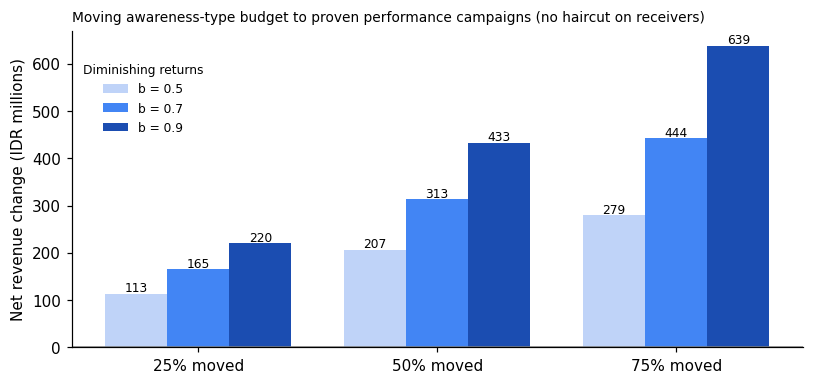

In [10]:
fig, ax = plt.subplots(figsize=(7.5, 3.6))
shifts = [0.25, 0.50, 0.75]
width = 0.26
for i, b in enumerate([0.5, 0.7, 0.9]):
    vals = [scenario(s, b)["d_revenue"] / 1e6 for s in shifts]
    bars = ax.bar(np.arange(3) + (i - 1) * width, vals, width, label=f"b = {b}", color=["#BFD3F8", "#4285F4", "#1B4DB1"][i])
    for bar, v in zip(bars, vals):
        ax.text(bar.get_x() + bar.get_width() / 2, v + (4 if v >= 0 else -14), f"{v:,.0f}", ha="center", fontsize=8)
ax.axhline(0, color="#888", lw=1)
ax.set_xticks(range(3), ["25% moved", "50% moved", "75% moved"])
ax.set_ylabel("Net revenue change (IDR millions)")
ax.set_title("Moving awareness-type budget to proven performance campaigns (no haircut on receivers)", fontsize=9, loc="left")
ax.legend(frameon=False, title="Diminishing returns", fontsize=8, title_fontsize=8, loc="upper left", bbox_to_anchor=(0.0, 0.93))
save_fig("budget_shift_scenarios")

### How wrong could the attribution be?

Awareness campaigns may be creating demand that brand search and retargeting then collect. If so, cutting them loses revenue that the numbers above credit to other campaigns. The question is how large that effect must be before the 50% shift stops paying off. Call `h` the share of brand-search and retargeting revenue that was really caused by the awareness-type campaigns, and assume it falls in step with their spend.

In [11]:
H_REV = harvest.net_revenue.sum()
shift, b = 0.50, 0.7
base = scenario(shift, b)
cut_fraction = 1 - (1 - shift) ** b           # share of revenue lost when donor spend is halved
h_break_even = base["d_revenue"] / (H_REV * cut_fraction)

print(f"Brand search and retargeting net revenue: IDR {H_REV/1e6:,.0f}M")
print(f"50% shift, b = 0.7: direct net revenue change IDR {base['d_revenue']/1e6:+,.0f}M")
print(f"Break-even halo: if {h_break_even:.0%} of that harvested revenue was caused by the awareness-type campaigns, the shift gains nothing.")

print("\nNet revenue change of the 50% shift for different halo shares (IDR millions):")
for h in [0, 0.10, 0.25, 0.50]:
    print(f"  halo {h:>4.0%}: {(base['d_revenue'] - h * H_REV * cut_fraction)/1e6:+,.0f}")

Brand search and retargeting net revenue: IDR 903M
50% shift, b = 0.7: direct net revenue change IDR +313M
Break-even halo: if 90% of that harvested revenue was caused by the awareness-type campaigns, the shift gains nothing.

Net revenue change of the 50% shift for different halo shares (IDR millions):
  halo   0%: +313
  halo  10%: +278
  halo  25%: +226
  halo  50%: +139

## What I would recommend

The recommendation is a test with a known cost, not a permanent reallocation.

1. **Move 50% of awareness-type spend into performance campaigns for one quarter.** That is about IDR 259 million out of 518 million. Under the central assumptions it adds about IDR 313 million of net revenue, 12% of the total, without extra budget. Across the assumptions I tested, the range for this shift is IDR 127 million to 433 million.
2. **Choose receivers by type, not by this quarter's ranking.** Live shopping, shopping/PMax, micro-influencer and conversion campaigns on Meta have a track record across several months. Cap growth at +100% per campaign and watch marginal ROAS weekly.
3. **Keep a holdout.** Keep awareness running unchanged in one region or on one channel. Compare brand-search volume and retargeting revenue against the reduced group. That measures the halo this analysis cannot see.
4. **Fix the two account problems first.** A budget guard would have prevented the single day that spent 7 times the normal amount, and a daily check on spend with zero conversions would have caught the broken pixel in a day instead of four.
5. **Reduce cash on delivery on TikTok.** COD is 35% of TikTok orders and about 16% of those are cancelled. A small deposit or a QRIS discount for first orders would convert some of that into completed revenue.
6. **Use double dates and paydays.** Conversion rate on double dates is about 1.7 times a regular weekday while spend barely moves. Raising budgets on those days is cheap to test.

### Limits of this analysis

- All figures are revenue. Without product cost, the rupiah value of a shift is smaller than the revenue change suggests.
- The curvature `b` is assumed. The net revenue change is positive in all 18 combinations I ran and the break-even halo is 90%, but the size of the gain depends on `b`.
- Attribution is last-click inside the platforms. Awareness effects are probably undercounted.
- The data is simulated. The method carries over to real data. The numbers do not.